In [7]:
from typing import TypedDict , Dict , List
from langgraph.graph import StateGraph , START , END
import random

In [8]:
class AgentState(TypedDict):
    name : str
    num : List[int]
    counter : int

In [9]:
def greet(state:AgentState)->AgentState:
    """ greet the user """
    state['name'] = f"hi  {state['name']}"
    state['counter'] = 0
    return state

def rand_num(state:AgentState)->AgentState:
    """ generate random numer"""
    state['num'].append(random.randint(1,21))
    state['counter'] +=1 
    return state

def continue_or_not(state:AgentState)->str:
    """check me """
    if state['counter'] < 15:
        print(f"\t - {state['counter']}")
        return 'loop'
    return 'exit'

In [10]:
graph = StateGraph(AgentState)

graph.add_edge(START , 'greet')

graph.add_node('greet', greet)

graph.add_edge('greet', 'rand_num')

graph.add_node('rand_num', rand_num)

graph.add_conditional_edges(
    'rand_num',
    continue_or_not,{
        'loop' : 'rand_num',
        'exit': END
    }
)

app = graph.compile()


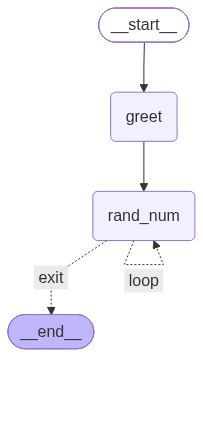

In [11]:
app

In [12]:
res = app.invoke({
    'name':'dev',
    'num' :[],
    'counter':0
})

res


	 - 1
	 - 2
	 - 3
	 - 4
	 - 5
	 - 6
	 - 7
	 - 8
	 - 9
	 - 10
	 - 11
	 - 12
	 - 13
	 - 14


{'name': 'hi  dev',
 'num': [14, 21, 14, 1, 14, 18, 11, 2, 18, 20, 2, 21, 1, 19, 2],
 'counter': 15}